<a href="https://colab.research.google.com/github/Aaarkun/rfm-transaction-analytics/blob/main/%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B0_%D1%80%D0%BE%D0%B1%D0%BE%D1%82%D0%B0_2_3_%D0%97%D0%B0%D1%85%D0%B0%D1%80%D0%B5%D0%B2%D0%B8%D1%87_3_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Пактична робота № 2_3


Аналіз коефіцієнта народжуваності в регіонах України (1950—2019)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from io import StringIO

In [3]:
# Отримуємо дані з сайту та чистимо таблицю

url = "https://uk.wikipedia.org/wiki/Населення_України"
headers = {"User-Agent": "Mozilla/5.0 (student project)"}
response = requests.get(url, headers=headers)

all_tables = pd.read_html(StringIO(response.text))

df = None
for table in all_tables:
    text = table.to_string()
    if "Волинська" in text and "Львівська" in text and table.shape[1] > 5:
        df = table
        break

if df is None:
    print("Таблицю не знайдено автоматично")
else:
    print("Таблицю знайдено", df.shape)

Таблицю знайдено (28, 9)


In [4]:
# Прибирає двоповерххові заголовки

if isinstance(df.columns, pd.MultiIndex):
    df.columns = [str(col[-1]) for col in df.columns]

df.columns = [str(col).strip() for col in df.columns]
df = df.rename(columns={df.columns[0]: "Регіон"})
df.head()
print("Рядків і стовпців:", df.shape)
print("Назви стовпців:", list(df.columns))

Рядків і стовпців: (28, 9)
Назви стовпців: ['Регіон', '1950', '1960', '1970', '1990', '2000', '2012', '2014', '2019']


In [5]:
#Видаляємо зайві стовпці

unnamed_cols = [col for col in df.columns if "Unnamed" in col]
df = df.drop(columns=unnamed_cols)

print( list(df.columns))

['Регіон', '1950', '1960', '1970', '1990', '2000', '2012', '2014', '2019']


In [6]:
#Замінюємо "—" на NaN та працюємо з пропусками
df = df.replace(["—", "–", "-"], np.nan)

for col in df.columns:
    if col == "Регіон":
        continue
    df[col] = (
        df[col]
        .astype(str)
        .str.replace(r"\[.*?\]", "", regex=True)
        .str.replace(",", ".", regex=False)
        .str.replace("\xa0", "", regex=False)
        .str.strip()
    )
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["Регіон"] = df["Регіон"].astype(str).str.replace(r"\[.*?\]", "", regex=True).str.strip()

In [7]:
# Перевіряємо пропущені значення
print("Пропуски по стовпцях:")
print(df.isna().sum())

df = df.dropna(axis=1, how="all")
year_cols = [col for col in df.columns if col != "Регіон"]
df_raw = df.copy()

# Показуємо де саме були пропуски
print("\nРядки з пропусками:")
print(df[df[year_cols].isna().any(axis=1)])

is_total = df["Регіон"].str.contains("Україна", case=False)
means = df.loc[~is_total, year_cols].mean()
df[year_cols] = df[year_cols].fillna(means)
print("\nПропусків після заміни:", df.isna().sum().sum())

Пропуски по стовпцях:
Регіон    0
1950      2
1960      1
1970      1
1990      0
2000      0
2012      0
2014      2
2019      4
dtype: int64

Рядки з пропусками:
         Регіон   1950   1960   1970  1990  2000  2012   2014   2019
0          Крим  230.0  206.0  160.0   130    73   126    NaN    NaN
4      Донецька  271.0  214.0  140.0   109    61    98   82.0    NaN
11    Луганська  262.0  235.0  144.0   116    62    96   51.0    NaN
25         Київ    NaN  174.0  159.0   120    73   120  121.0  110.0
26  Севастополь    NaN    NaN    NaN   125    70   120    NaN    NaN

Пропусків після заміни: 0


In [8]:
#Перевіряємо дублікати
print("Кількість дублікатів:", df.duplicated().sum())
df = df.drop_duplicates()
print("Розмір після видалення дублікатів:", df.shape)

Кількість дублікатів: 0
Розмір після видалення дублікатів: (28, 9)


In [9]:
#Описова статистика
df.describe()

,1950,1960,1970,1990,2000,2012,2014,2019
count,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000
mean,230.931429,207.484890,155.857143,130.428571,82.071429,116.464286,111.424286,80.203416
std,27.155159,28.811488,18.353957,15.278716,15.568079,16.362745,19.356640,13.385955
min,186.000000,163.000000,127.000000,108.000000,61.000000,94.000000,51.000000,60.000000
25%,212.500000,187.750000,144.000000,122.250000,70.750000,104.500000,104.750000,70.250000
50%,229.000000,204.500000,153.500000,126.000000,78.500000,114.500000,111.440000,80.086957
75%,244.000000,219.250000,161.500000,140.500000,89.500000,122.500000,121.000000,87.250000
max,314.000000,273.000000,207.000000,168.000000,118.000000,159.000000,148.000000,110.000000


In [10]:
# Підготовка для аналізу
first_year = year_cols[0]
last_year = year_cols[-1]
print("Перший рік:", first_year, "| Останній рік:", last_year)

df_regions = df[~df["Регіон"].str.contains("Україна", case=False)].copy()

Перший рік: 1950 | Останній рік: 2019


In [11]:
#Зміна народжуваності між першим і останнім роком

df_regions["Зміна"] = (
    df_raw.loc[df_regions.index, last_year] - df_raw.loc[df_regions.index, first_year]
)
real_change = df_regions.dropna(subset=["Зміна"])
print(f"Регіони, де народжуваність впала найбільше ({first_year} -> {last_year}):")
print(real_change.sort_values("Зміна").head(5)[["Регіон", first_year, last_year, "Зміна"]])
print("\nРегіони, де народжуваність впала найменше:")
print(real_change.sort_values("Зміна").tail(5)[["Регіон", first_year, last_year, "Зміна"]])

Регіони, де народжуваність впала найбільше (1950 -> 2019):
          Регіон   1950   2019  Зміна
6   Закарпатська  314.0  104.0 -210.0
5    Житомирська  261.0   79.0 -182.0
16    Рівненська  269.0  107.0 -162.0
24  Чернігівська  220.0   61.0 -159.0
17       Сумська  216.0   60.0 -156.0

Регіони, де народжуваність впала найменше:
              Регіон   1950  2019  Зміна
3   Дніпропетровська  204.0  71.0 -133.0
19        Харківська  197.0  68.0 -129.0
20        Херсонська  208.0  81.0 -127.0
9           Київська  204.0  80.0 -124.0
15        Полтавська  186.0  65.0 -121.0


In [12]:
#Найвища та найнижча народжуваність в останньому році
best = df_regions.loc[df_regions[last_year].idxmax()]
worst = df_regions.loc[df_regions[last_year].idxmin()]
print(f"Найвища народжуваність у {last_year}: {best['Регіон']} ({best[last_year]})")
print(f"Найнижча народжуваність у {last_year}: {worst['Регіон']} ({worst[last_year]})")

Найвища народжуваність у 2019: Київ (110.0)
Найнижча народжуваність у 2019: Сумська (60.0)


In [13]:
#Кореляція між роками
corr = df_regions[year_cols].corr()
print(corr.round(2))
corr_pairs = corr.where(~np.eye(len(corr), dtype=bool)).stack()
print("\nНайвища кореляція:", corr_pairs.idxmax(), "->", round(corr_pairs.max(), 2))
print("Найнижча кореляція:", corr_pairs.idxmin(), "->", round(corr_pairs.min(), 2))

      1950  1960  1970  1990  2000  2012  2014  2019
1950  1.00  0.78  0.63  0.49  0.52  0.57  0.29  0.67
1960  0.78  1.00  0.84  0.78  0.74  0.70  0.44  0.66
1970  0.63  0.84  1.00  0.93  0.86  0.90  0.77  0.80
1990  0.49  0.78  0.93  1.00  0.94  0.84  0.77  0.65
2000  0.52  0.74  0.86  0.94  1.00  0.85  0.81  0.66
2012  0.57  0.70  0.90  0.84  0.85  1.00  0.89  0.83
2014  0.29  0.44  0.77  0.77  0.81  0.89  1.00  0.65
2019  0.67  0.66  0.80  0.65  0.66  0.83  0.65  1.00

Найвища кореляція: ('1990', '2000') -> 0.94
Найнижча кореляція: ('1950', '2014') -> 0.29


## Графіки

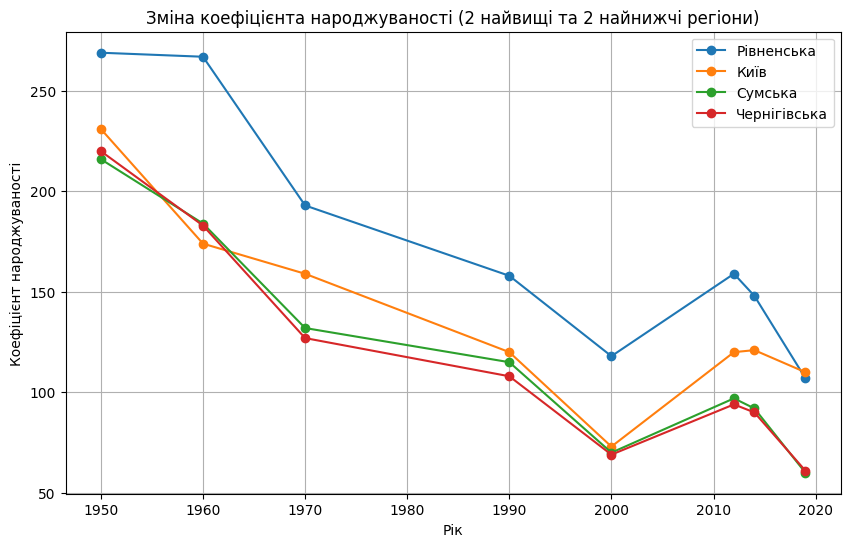

In [14]:
# Графік 1. Лінійний: як змінювалась народжуваність
top2 = df_regions.sort_values(last_year).tail(2)
bottom2 = df_regions.sort_values(last_year).head(2)
selected = pd.concat([top2, bottom2])

years = [int(y) for y in year_cols]

plt.figure(figsize=(10, 6))
for _, row in selected.iterrows():
    plt.plot(years, row[year_cols].values, marker="o", label=row["Регіон"])

plt.title("Зміна коефіцієнта народжуваності (2 найвищі та 2 найнижчі регіони)")
plt.xlabel("Рік")
plt.ylabel("Коефіцієнт народжуваності")
plt.legend()
plt.grid(True)
plt.show()

У всіх чотирьох регіонах народжуваність різко впала з 1950 до 2000 року:
приблизно з 200-270 до 70-120. Після 2000 року було невелике зростання (до 2012),а до 2019 року показники знову знизились. У 2019 році найвищі значення у Києвf та Рівненської області, найнижчі - у Сумської та Чернігівської.
Для Києва значення за 1950 рік було пропущене і заповнене середнім.

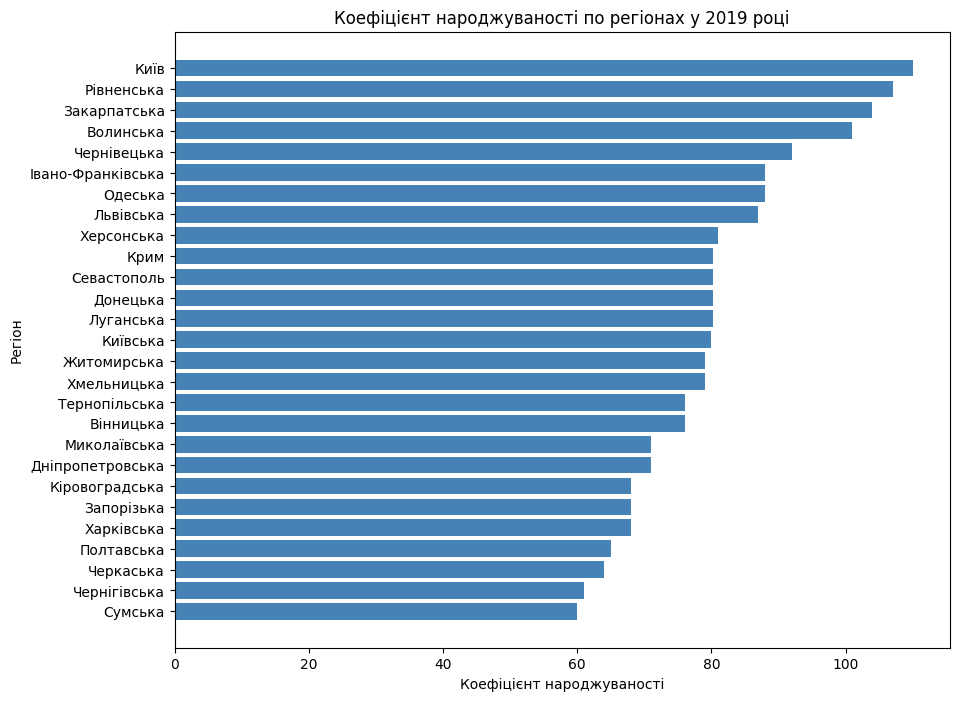

In [15]:
# Графік 2. Стовпчиковий: народжуваність по регіонах в останньому році
sorted_regions = df_regions.sort_values(last_year)

plt.figure(figsize=(10, 8))
plt.barh(sorted_regions["Регіон"], sorted_regions[last_year], color="steelblue")
plt.title(f"Коефіцієнт народжуваності по регіонах у {last_year} році")
plt.xlabel("Коефіцієнт народжуваності")
plt.ylabel("Регіон")
plt.show()

У 2019 році найвища народжуваність у Києві (110), Рівненській (107) та Закарпатській (104) областях, найнижча - у Сумській (60), Чернігівській (61) та Черкаській (64). Середнє значення по регіонах приблизно 80.

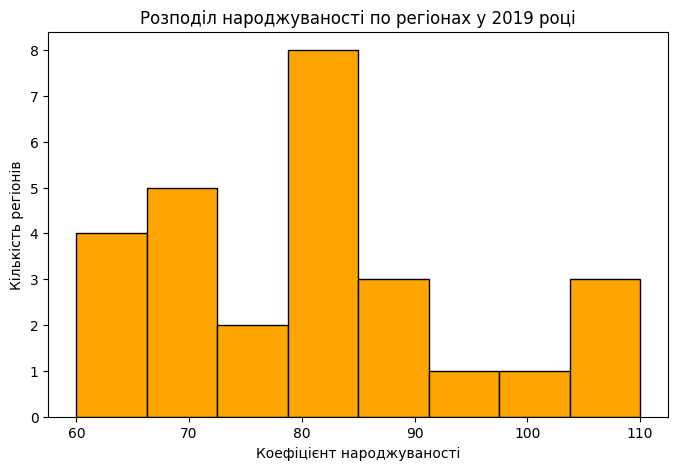

In [16]:
# Графік 3. Гістограма: розподіл значень в останньому році
plt.figure(figsize=(8, 5))
plt.hist(df_regions[last_year], bins=8, color="orange", edgecolor="black")
plt.title(f"Розподіл народжуваності по регіонах у {last_year} році")
plt.xlabel("Коефіцієнт народжуваності")
plt.ylabel("Кількість регіонів")
plt.show()

Значення за 2019 рік лежать у межах від 60 до 110. Більшість регіонів зібралась
у діапазоні приблизно 60-85, а високі значення (понад 98) мають лише кілька
регіонів, тому розподіл трохи зміщений вправо. Найвищий стовпчик (79-85)частково штучний: туди потрапили 4 регіони із заповненими середнім значеннями.

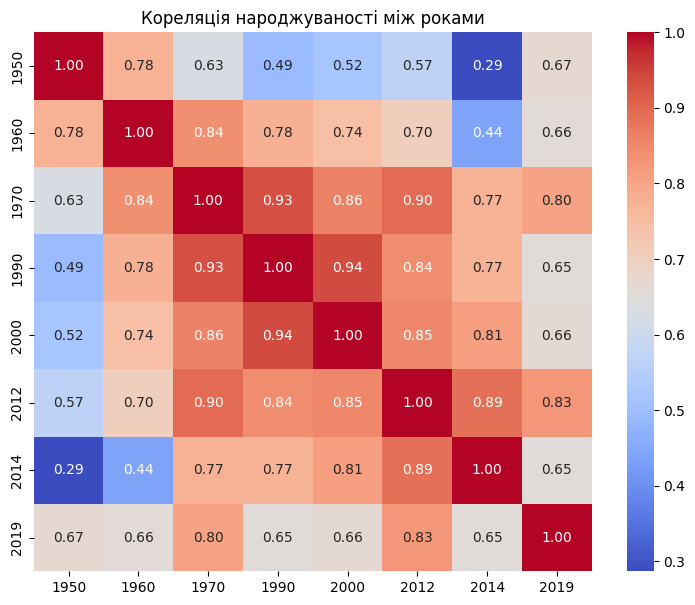

In [17]:
# Графік 4. Теплова карта кореляцій між роками
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Кореляція народжуваності між роками")
plt.show()

Найсильніша кореляція між 1990 і 2000 роками (0.94) та між 1970 і 1990 (0.93):
регіони, які мали високу народжуваність раніше, здебільшого зберігали її й пізніше.
Найслабший зв'язок між 1950 і 2014 роками (0.29): чим більша різниця в роках,
тим слабше схожі розподіли. На 2014 рік, імовірно, вплинули аномальні дані
(наприклад, Луганська область має лише 51) та заповнені значення.

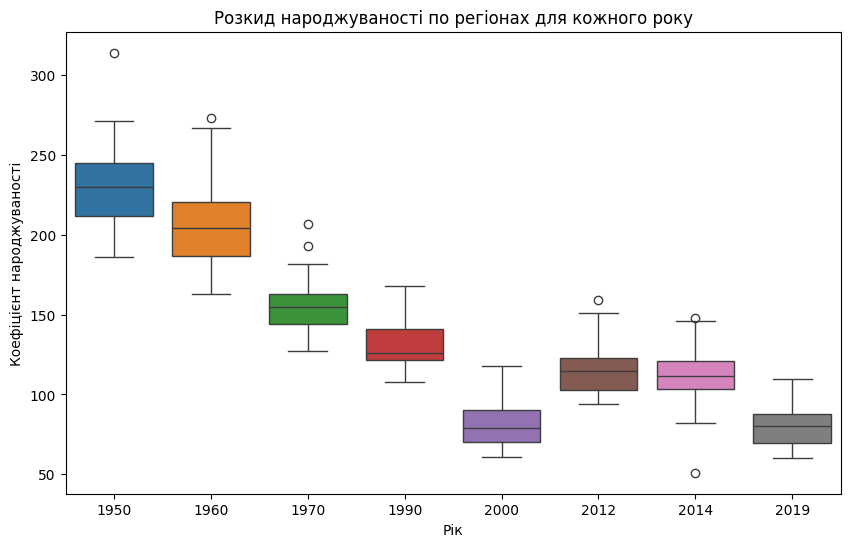

In [18]:
# Графік 5. Boxplot: розкид значень по регіонах для кожного року
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_regions[year_cols])
plt.title("Розкид народжуваності по регіонах для кожного року")
plt.xlabel("Рік")
plt.ylabel("Коефіцієнт народжуваності")
plt.show()

Медіана народжуваності по регіонах падала з 230 (1950) до 79 (2000), потім
зросла до ~115 (2012) і знову знизилась до ~80 (2019). Розкид між регіонами
був найбільшим у 1950 і 1960 роках (великі "коробки" та вуса), а з 1970 року
регіони стали більш схожими між собою. У 2014 році видно викид унизу
(Луганська область). Медіана 2019 року частково спирається на заповнені значення.